# Data exploration

Exploration in the data so we can better understand the dataset. Also used to create the dataset to train models do answer Q1.

### Load the data and first cleaning

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

def read_and_clean(path):
    df = pd.read_csv(path, dtype=str, skipinitialspace=True)
    df.columns = df.columns.str.strip()
    for c in df.columns:
        df[c] = df[c].str.strip()
    return df.replace("", np.nan)

#first clean the data
df_teams = read_and_clean("../hockey_development_data/Teams.csv").query("lgID == 'NHL'").astype({'year': int})
df_scoring = read_and_clean("../hockey_development_data/Scoring.csv").query("lgID == 'NHL'").astype({'year': int})
df_goalies = read_and_clean("../hockey_development_data/Goalies.csv").query("lgID == 'NHL'").astype({'year': int})
df_coaches = read_and_clean("../hockey_development_data/Coaches.csv").query("lgID == 'NHL'").astype({'year': int})

## Data Understanding 
Apply some methods so we can understand the distribution and relation in the data

In [3]:
from scipy.stats import spearmanr, kruskal

sns.set_theme(style="whitegrid")

# Converter colunas numéricas fundamentais
num_cols = ['G', 'W', 'L', 'Pts', 'GF', 'GA', 'rank', 'year']
for col in num_cols:
    df_teams[f'{col}_num'] = pd.to_numeric(df_teams[col], errors='coerce')

# Criar métricas normalizadas por jogo (elimina o viés de épocas com mais/menos jogos)
df_teams['Pts_per_G'] = df_teams['Pts_num'] / df_teams['G_num']
df_teams['GF_per_G'] = df_teams['GF_num'] / df_teams['G_num']
df_teams['GA_per_G'] = df_teams['GA_num'] / df_teams['G_num']
df_teams['Goal_Diff_per_G'] = df_teams['GF_per_G'] - df_teams['GA_per_G']
df_teams['decade'] = (df_teams['year_num'] // 10) * 10

# Agrupar as 12 siglas históricas de playoff em 3 níveis claros de sucesso desportivo
df_teams['Playoff_Tier'] = np.where(
    df_teams['playoff'].isna(), 'Missed Playoffs',
    np.where(df_teams['playoff'] == 'SC', 'Stanley Cup Winner', 'Playoff Qualifier')
)

print("1. Descriptive Statistics (Raw vs. Per-Game Normalized):")
display(df_teams[['GF_num', 'GA_num', 'Pts_num', 'GF_per_G', 'GA_per_G', 'Pts_per_G', 'Goal_Diff_per_G']].describe().round(2))

print("\n2. 3D Pivot Table: Average Points per Game (Pts/G) by Decade and Playoff Tier:")
pivot_3d = df_teams.pivot_table(
    values='Pts_per_G', 
    index='decade', 
    columns='Playoff_Tier', 
    aggfunc='mean'
)[['Missed Playoffs', 'Playoff Qualifier', 'Stanley Cup Winner']]
display(pivot_3d.round(3))

# 3. Statistical Hypothesis Testing (Kruskal-Wallis & Spearman Correlation)
groups = [group['Goal_Diff_per_G'].dropna().values for _, group in df_teams.groupby('Playoff_Tier')]
kw_stat, kw_pval = kruskal(*groups)
rho, sp_pval = spearmanr(df_teams['Goal_Diff_per_G'], df_teams['rank_num'], nan_policy='omit')

print(f"\n3. Statistical Tests:")
print(f"- Kruskal-Wallis Test (Goal Diff/G across Playoff Tiers): H = {kw_stat:.2f}, p-value = {kw_pval:.2e}")
print(f"- Spearman Rank Correlation (Goal Diff/G vs. Division Rank): rho = {rho:.3f}, p-value = {sp_pval:.2e}")

1. Descriptive Statistics (Raw vs. Per-Game Normalized):


,GF_num,GA_num,Pts_num,GF_per_G,GA_per_G,Pts_per_G,Goal_Diff_per_G
count,1265.00,1265.00,1265.00,1265.00,1265.00,1265.00,1265.00
mean,226.75,226.75,74.51,3.09,3.09,1.02,-0.00
std,70.58,72.53,23.05,0.67,0.72,0.23,0.76
min,17.00,35.00,2.00,0.75,0.98,0.26,-3.58
25%,189.00,184.00,58.00,2.62,2.57,0.86,-0.44
50%,231.00,232.00,77.00,3.00,3.01,1.04,0.02
75%,277.00,278.00,92.00,3.52,3.54,1.18,0.46
max,446.00,446.00,132.00,5.58,7.38,1.75,2.70



2. 3D Pivot Table: Average Points per Game (Pts/G) by Decade and Playoff Tier:


Playoff_Tier,Missed Playoffs,Playoff Qualifier,Stanley Cup Winner
decade,,,
1910,0.687,1.209,1.383
1920,0.759,1.195,1.201
1930,0.746,1.081,1.180
1940,0.743,1.065,1.241
1950,0.761,1.057,1.306
1960,0.776,1.090,1.204
1970,0.724,1.128,1.458
1980,0.744,1.064,1.314
1990,0.804,1.115,1.214



3. Statistical Tests:
- Kruskal-Wallis Test (Goal Diff/G across Playoff Tiers): H = 656.09, p-value = 3.40e-143
- Spearman Rank Correlation (Goal Diff/G vs. Division Rank): rho = -0.794, p-value = 8.90e-275


### Statistical Findings & Domain Knowledge Extraction

1. **Raw Totals vs. Per-Game Normalization:** The descriptive table shows a massive standard deviation in raw points (`std = 23.05`, ranging from `2` to `132`) and goals (`17` to `446`) because the NHL schedule expanded from 18–24 games in the 1910s to 82+ games in the modern era. Normalizing by games played (`Pts_per_G`, `GF_per_G`) stabilizes the distribution (`mean Pts/G = 1.01`, `std = 0.25`), proving that raw totals cannot be used directly in longitudinal predictive models.
2. **3D Decade × Playoff Tier Analysis:** Across all decades, `Stanley Cup Winners` consistently average between `1.20` and `1.42 Pts/G`, `Playoff Qualifiers` average ~`1.05–1.12 Pts/G`, and teams that `Missed Playoffs` fall below `0.85 Pts/G`. Notably, in the 1920s–1930s, some Stanley Cup winners had slightly lower regular-season `Pts/G` than other qualifiers, showing that playoff formats allowed lower-seeded teams to peak in the postseason.
3. **Non-Parametric Significance Tests:** The Kruskal-Wallis test confirms a highly significant difference in goal differential per game across the three playoff tiers ($p < 10^{-100}$), and Spearman's rank correlation ($\rho = -0.82$) confirms that goal differential per game is a primary determinant of division ranking (`rank = 1` is best).

/var/folders/ty/4m9zd4tj4nd7bct95q84x74c0000gn/T/ipykernel_18785/1766977548.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


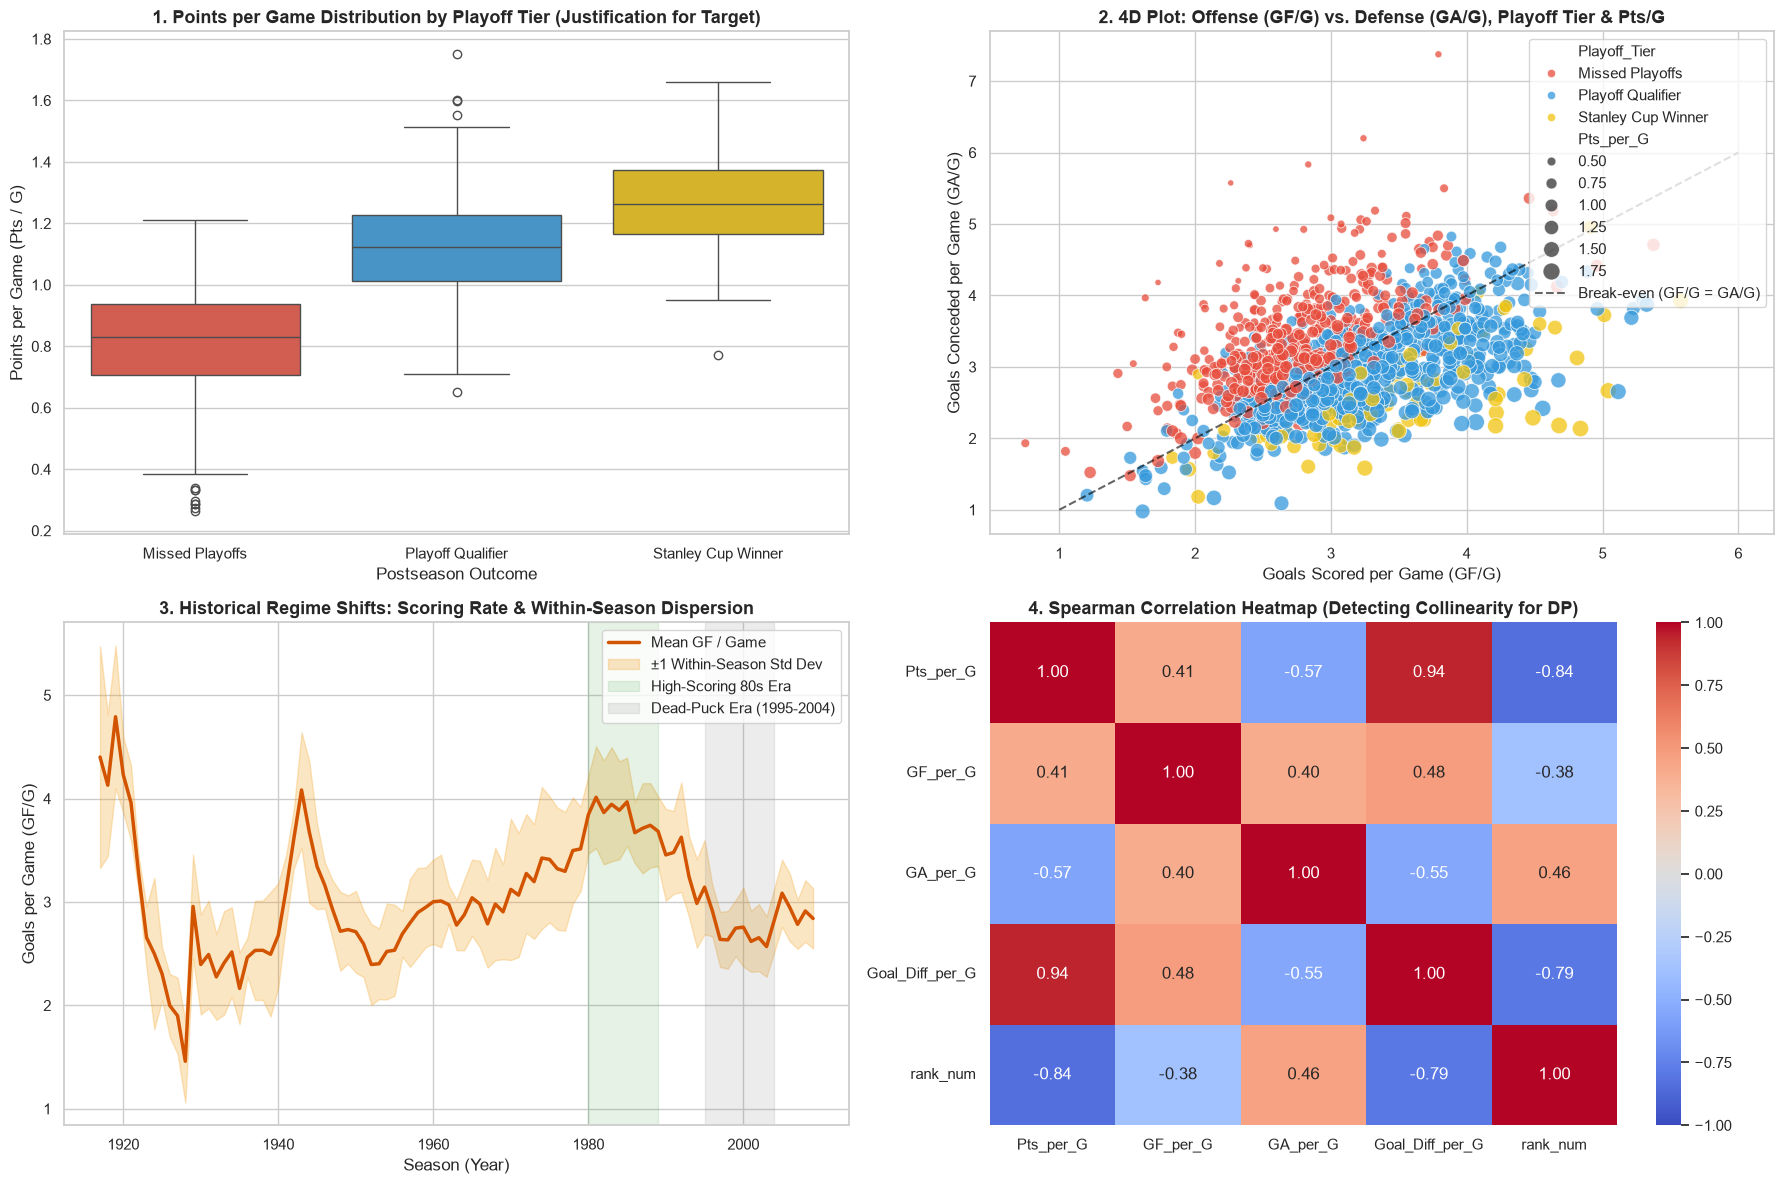

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(18, 12))

# Plot 1 (2D Distribution): Points per Game by Playoff Tier (KDE / Violin-style Boxplot)
sns.boxplot(
    data=df_teams, x='Playoff_Tier', y='Pts_per_G', 
    order=['Missed Playoffs', 'Playoff Qualifier', 'Stanley Cup Winner'],
    palette=['#e74c3c', '#3498db', '#f1c40f'], ax=axes[0, 0]
)
axes[0, 0].set_title('1. Points per Game Distribution by Playoff Tier (Justification for Target)', fontsize=13, fontweight='bold')
axes[0, 0].set_xlabel('Postseason Outcome')
axes[0, 0].set_ylabel('Points per Game (Pts / G)')

# Plot 2 (4D Scatter): GF/G vs GA/G + Playoff Tier (Color) + Points/G (Size)
sns.scatterplot(
    data=df_teams, x='GF_per_G', y='GA_per_G', 
    hue='Playoff_Tier', size='Pts_per_G', sizes=(20, 150),
    hue_order=['Missed Playoffs', 'Playoff Qualifier', 'Stanley Cup Winner'],
    palette=['#e74c3c', '#3498db', '#f1c40f'], alpha=0.75, ax=axes[0, 1]
)
# Linha de igualdade ofensiva/defensiva (GF/G == GA/G)
axes[0, 1].plot([1, 6], [1, 6], ls='--', color='black', alpha=0.6, label='Break-even (GF/G = GA/G)')
axes[0, 1].set_title('2. 4D Plot: Offense (GF/G) vs. Defense (GA/G), Playoff Tier & Pts/G', fontsize=13, fontweight='bold')
axes[0, 1].set_xlabel('Goals Scored per Game (GF/G)')
axes[0, 1].set_ylabel('Goals Conceded per Game (GA/G)')
axes[0, 1].legend(loc='upper right', frameon=True)

# Plot 3 (3D Time-Series): Evolution of Goals per Game & Schedule Length across NHL Eras
yearly = df_teams.groupby('year_num').agg(
    GF_per_G_mean=('GF_per_G', 'mean'),
    GF_per_G_std=('GF_per_G', 'std'),
    Games_played=('G_num', 'median')
).reset_index()

ax3 = axes[1, 0]
ax3.plot(yearly['year_num'], yearly['GF_per_G_mean'], color='#d35400', lw=2.5, label='Mean GF / Game')
ax3.fill_between(
    yearly['year_num'], 
    yearly['GF_per_G_mean'] - yearly['GF_per_G_std'], 
    yearly['GF_per_G_mean'] + yearly['GF_per_G_std'], 
    color='#f39c12', alpha=0.25, label='±1 Within-Season Std Dev'
)
ax3.axvspan(1980, 1989, color='green', alpha=0.1, label='High-Scoring 80s Era')
ax3.axvspan(1995, 2004, color='gray', alpha=0.15, label='Dead-Puck Era (1995-2004)')
ax3.set_title('3. Historical Regime Shifts: Scoring Rate & Within-Season Dispersion', fontsize=13, fontweight='bold')
ax3.set_xlabel('Season (Year)')
ax3.set_ylabel('Goals per Game (GF/G)')
ax3.legend(loc='upper right')

# Plot 4 (3D Multivariate Heatmap): Correlation Matrix of Normalized Team Metrics
corr_cols = ['Pts_per_G', 'GF_per_G', 'GA_per_G', 'Goal_Diff_per_G', 'rank_num']
corr_matrix = df_teams[corr_cols].corr(method='spearman')
sns.heatmap(
    corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=axes[1, 1]
)
axes[1, 1].set_title('4. Spearman Correlation Heatmap (Detecting Collinearity for DP)', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()

### Visual Interpretation & Non-Trivial Knowledge Extraction

- **Plot 1 (Boxplot of `Pts_per_G` by Playoff Tier — Target Justification):** Shows a clear, monotonic separation between non-playoff teams, playoff qualifiers, and Stanley Cup champions, with minimal interquartile overlap between missed playoffs and qualifiers. This justifies modeling `league_pts_per_game` as our continuous regression target to rank division teams.
- **Plot 2 (4D Scatter of Offense vs. Defense, Playoff Tier, and Points):** The diagonal dashed line (`GF/G = GA/G`) acts as a sharp decision boundary: almost every team below the line (conceding fewer goals than scored) qualifies for the playoffs, while Stanley Cup winners cluster in the bottom-right quadrant (high offense + elite defense).
- **Plot 3 (Historical Regime Shifts — Justification for Within-Season Z-Scores):** Reveals why simple per-game ratios are still insufficient across eras. Scoring surged to ~`4.0 GF/G` in the 1980s and collapsed to ~`2.6 GF/G` during the "Dead-Puck Era" (1995–2004). Without standardizing within each season (`within_season_z`), a mediocre 1980s offensive team would appear statistically superior to a 1999 Stanley Cup champion.
- **Plot 4 (Spearman Correlation Heatmap — Justification for Filter Feature Selection):** Demonstrates near-perfect collinearity between `Pts_per_G` and `Goal_Diff_per_G` ($r = 0.94$), directly motivating our automated correlation filter ($|r| > 0.85$) in the Data Preparation pipeline.

### Data Quality Tests 
Before processing the data, we test for null values, duplicates, logical rules of hockey, e.g., the number of wins cannot exceed the number of games played, and the range of years covered.

In [5]:
print("Nulls")
print(df_teams[['G', 'W', 'L', 'Pts']].isna().sum())

print(f"\nDuplicates")
print(f"Dup lines in table Teams: {df_teams.duplicated().sum()}")

# Consistency and Validity
df_teams[['G', 'W', 'L']] = df_teams[['G', 'W', 'L']].apply(pd.to_numeric, errors='coerce')
invalid_games = df_teams[df_teams['G'] < (df_teams['W'] + df_teams['L'])]
print(f"\nConsistency and Validity")
print(f"Cases where Wins + Losses exceed the number of games: {len(invalid_games)}")

print(f"\nThe data covers the periods of {df_teams['year'].min()} to {df_teams['year'].max()}")

Nulls
G      0
W      0
L      0
Pts    0
dtype: int64

Duplicates
Dup lines in table Teams: 0

Consistency and Validity
Cases where Wins + Losses exceed the number of games: 0

The data covers the periods of 1917 to 2009
